<a href="https://colab.research.google.com/github/vzavala/DesignOfExperiments/blob/main/Python/ch5_heat_capacity_uncertainty.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Setup.** Run this cell first: it locates the data files this notebook reads. On Google
Colab it downloads them (the `Data/` and `Support/` folders) from the book's GitHub
repository; on your computer, run the notebook from the folder that contains `Data/`.

In [1]:
import os
import sys
path = ''
if 'google.colab' in sys.modules and not os.path.isdir('Data'):
    if not os.path.isdir('statsbook'):
        os.system('git clone -q --depth 1 --filter=blob:none --sparse '
                  'https://github.com/vzavala/DesignOfExperiments.git statsbook')
        os.system('git -C statsbook sparse-checkout set Python/Data Python/Support')
    path = 'statsbook/Python/'

Uncertainty quantification for the heat-capacity model (Victor Z and Jaron T, UW-Madison, 2024).

| Slides | Python | Meaning |
|---|---|---|
| $\hat{\theta}$, $\mathrm{Cov}[\hat{\theta}]$ | `theta_hat`, `Cov_theta` | estimate and its covariance |
| $q_{n+1}$ | `q_np1` | 0.95 quantile of $\chi^2(n+1)$ |
| $m_i=\sqrt{q_{n+1}\mathrm{Cov}[\hat{\theta}]_{ii}}$ | `m_theta` | parameter CI half-widths |
| $\mathrm{Cov}[\hat{\mathbf{y}}]=\mathbf{X}\mathrm{Cov}[\hat{\theta}]\mathbf{X}^T$ | `Cov_y` | prediction covariance |
| $q_S$, $m_\omega$ | `q_S`, `m_y` | 0.95 quantile of $\chi^2(S)$ and prediction CI half-widths |

**Note:** This notebook reproduces Example 5.7 (Section 5.2.3) of *Statistics for Chemical Engineers*: confidence ellipses for the parameters and confidence intervals for the predictions.

**The concept.** The least-squares estimate is a linear function of the Gaussian data, so $\hat{\theta}\sim\mathcal{N}(\theta,\mathrm{Cov}[\hat{\theta}])$ with $\mathrm{Cov}[\hat{\theta}]=\hat{\sigma}^2(\mathbf{X}^T\mathbf{X})^{-1}$. Then

$$(\theta-\hat{\theta})^T\,\mathrm{Cov}[\hat{\theta}]^{-1}(\theta-\hat{\theta})\sim\chi^2(n+1),$$

and the set where this quantity is at most $q_{n+1}$ (the 0.95 quantile) is an **ellipsoid** that contains the true parameters with probability 0.95. Its axes are the eigenvectors of $\mathrm{Cov}[\hat{\theta}]$, with half-lengths $\sqrt{q_{n+1}\lambda_i}$. Projecting the ellipsoid on each coordinate gives the half-widths $m_i$. Uncertainty in $\hat{\theta}$ propagates linearly to the predictions $\hat{\mathbf{y}}=\mathbf{X}\hat{\theta}$.

## Confidence intervals for the parameters

In [2]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2, norm
sys.path.append(path + 'Support')
from ellipse import ellipse

theta = np.array([6.190, 2.923e-3, -7.052e-7])
x = np.repeat([300.0, 600.0, 900.0], 10)
S = len(x)
X = np.column_stack([np.ones(S), x, x**2])
np.random.seed(0)
y = X @ theta + np.random.normal(0, 0.1, S)

theta_hat = np.linalg.solve(X.T @ X, X.T @ y)
y_hat = X @ theta_hat
sigma_hat = norm.fit(y - y_hat)[1]
Cov_theta = np.linalg.inv(X.T @ X) * sigma_hat**2

**From equation to code.** The quantile $q_{n+1}$ comes from the $\chi^2(n+1)$ distribution, and $m_i=\sqrt{q_{n+1}\,\mathrm{Cov}[\hat{\theta}]_{ii}}$ uses the diagonal of the covariance.

In [3]:
n_par = len(theta_hat)                         # n + 1 parameters
q_np1 = chi2.ppf(0.95, n_par)
m_theta = np.sqrt(q_np1 * np.diag(Cov_theta))
print(f"q_(n+1) = {q_np1:.2f}")
for i in range(n_par):
    print(f"theta_{i} = {theta_hat[i]: .3e} +/- {m_theta[i]:.2e}   (true {theta[i]: .3e})")

q_(n+1) = 7.81
theta_0 =  6.310e+00 +/- 4.08e-01   (true  6.190e+00)
theta_1 =  2.747e-03 +/- 1.54e-03   (true  2.923e-03)
theta_2 = -6.348e-07 +/- 1.27e-06   (true -7.052e-07)


95% confidence ellipses for pairs of parameters (deviations $\Delta\theta=\theta-\hat{\theta}$).

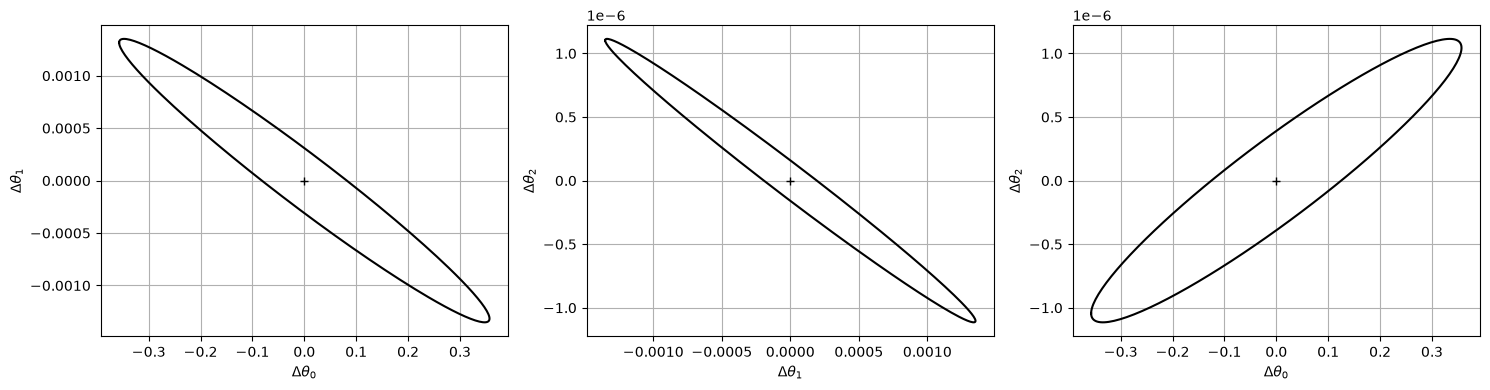

In [4]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
for ax, (i, j) in zip(axs, [(0, 1), (1, 2), (0, 2)]):
    C_ij = Cov_theta[np.ix_([i, j], [i, j])]
    xe, ye, _, _, _ = ellipse(np.linalg.inv(C_ij), chi2.ppf(0.95, 2), 200, [0, 0])
    ax.plot(xe, ye, 'k')
    ax.plot(0, 0, 'k+')
    ax.set_xlabel(rf'$\Delta\theta_{i}$')
    ax.set_ylabel(rf'$\Delta\theta_{j}$')
    ax.grid(True)
plt.tight_layout()
plt.show()

## Confidence intervals for the predictions

$\hat{\mathbf{y}}\sim\mathcal{N}(\mathbf{y},\mathbf{X}\mathrm{Cov}[\hat{\theta}]\mathbf{X}^T)$, so
$y_\omega=\hat{y}_\omega\pm m_\omega$ with $m_\omega=\sqrt{q_S\,\mathrm{Cov}[\hat{\mathbf{y}}]_{\omega\omega}}$.

q_S = 43.77  (S = 30)


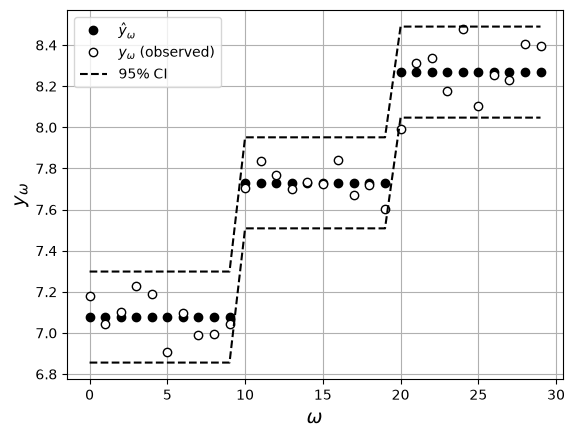

In [5]:
Cov_y = X @ Cov_theta @ X.T
q_S = chi2.ppf(0.95, S)
m_y = np.sqrt(q_S * np.diag(Cov_y))
print(f"q_S = {q_S:.2f}  (S = {S})")

plt.plot(y_hat, 'ko', markerfacecolor='black', label=r'$\hat{y}_\omega$')
plt.plot(y, 'ko', markerfacecolor='white', label=r'$y_\omega$ (observed)')
plt.plot(y_hat - m_y, 'k--', label='95% CI')
plt.plot(y_hat + m_y, 'k--')
plt.xlabel(r'$\omega$', fontsize=14)
plt.ylabel(r'$y_\omega$', fontsize=14)
plt.legend()
plt.grid(True)
plt.show()

For comparison, `statsmodels` reports the usual $t$-based (marginal) 95% intervals, which are
narrower than the joint $\chi^2(n+1)$ intervals above.

In [6]:
import statsmodels.api as sm
print(sm.OLS(y, X).fit().conf_int(0.05))

[[ 5.99478266e+00  6.62562366e+00]
 [ 1.55330619e-03  3.94114441e-03]
 [-1.61957716e-06  3.49878602e-07]]


**Check by simulation.** Repeat the experiment many times with new noise (known $\sigma$) and count how often the 95% ellipsoid contains the true parameters.

In [7]:
rng = np.random.default_rng(1)
Cov_known = np.linalg.inv(X.T @ X) * 0.1**2
inside = 0
for _ in range(20000):
    th = np.linalg.solve(X.T @ X, X.T @ (X @ theta + rng.normal(0, 0.1, S)))
    d = th - theta
    inside += d @ np.linalg.solve(Cov_known, d) <= q_np1
print(f"the ellipsoid contains the true parameters in {inside/20000:.1%} of the experiments")

the ellipsoid contains the true parameters in 95.1% of the experiments


**Note:** As in the book, the intervals for the predicted outputs are wide even though those of the parameters are small, because the measurement noise is large.